<a href="https://colab.research.google.com/github/sylle321/Hotel_booking/blob/main/Descriptive_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px                          # interactive plots (pre-installed on Colab)
from sklearn.preprocessing import StandardScaler     # does the scaling for us
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from tqdm import tqdm

path = "/content/hotels.csv"
df = pd.read_csv(path)
#Shows each columns data type and number of non-null values.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [24]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
#Counts distinct values in each column of the dataframe.
df.nunique()

,0
hotel,2
is_canceled,2
lead_time,479
arrival_date_year,3
arrival_date_month,12
arrival_date_week_number,53
arrival_date_day_of_month,31
stays_in_weekend_nights,17
stays_in_week_nights,35
adults,14


In [26]:
# Convert hotel to a dummy variable:
# Resort Hotel = 0, City Hotel = 1
df['hotel'] = df['hotel'].map({
    'Resort Hotel': 0,
    'City Hotel': 1
})

df.head()

# Create dummy variables for the other categorical variables
categorical_cols = [
    'deposit_type',
    'market_segment',
    'customer_type',
    'reserved_room_type'
]

df_encoded = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 49 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  int64  
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [27]:
# Selecting the columns of interest for analysis
# Making sure unrelated columns are not included in the analysis.
cols = [
    "hotel",
    "is_canceled",
    "lead_time",
    "deposit_type",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "customer_type",
    "booking_changes",
    "is_repeated_guest",
    "market_segment",
    "total_of_special_requests",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "reserved_room_type",
    "adr",
    "distribution_channel",
    "arrival_date_month"
]

hotel_selected = df[cols]

hotel_selected.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 17 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  int64  
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   deposit_type                    119390 non-null  object 
 4   previous_cancellations          119390 non-null  int64  
 5   previous_bookings_not_canceled  119390 non-null  int64  
 6   customer_type                   119390 non-null  object 
 7   booking_changes                 119390 non-null  int64  
 8   is_repeated_guest               119390 non-null  int64  
 9   market_segment                  119390 non-null  object 
 10  total_of_special_requests       119390 non-null  int64  
 11  stays_in_weekend_nights         119390 non-null  int64  
 12  stays_in_week_ni

In [28]:
#Cleaning the data by removing rows with any missing values and resetting the index.
hotel_clean = hotel_selected.dropna(how="any") #Removes rows with any missing values.
hotel_clean = hotel_clean.reset_index(drop=True) #resets the index

print(hotel_selected.shape)
print(hotel_clean.shape)

(119390, 17)
(119390, 17)


In [29]:
#Checking cancelation counts and proportions in the cleaned dataset.
print(hotel_clean["is_canceled"].value_counts()) #Gives the count of each unique value in the "is_canceled" column.

print(
    hotel_clean["is_canceled"].value_counts(normalize=True) # Gives the proportion of each unique value in the "is_canceled" column.
)


is_canceled
0    75166
1    44224
Name: count, dtype: int64
is_canceled
0    0.629584
1    0.370416
Name: proportion, dtype: float64


In [30]:
# Calculate the correlation using PCA lab's code as reference.
# We exclude categorical string columns and only keep truly numeric columns
numeric_cols = [
    "is_canceled",
    "lead_time",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "is_repeated_guest",
    "total_of_special_requests",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adr"
]

hotel_numeric = hotel_clean[numeric_cols]

corr_mat = hotel_numeric.corr()

corr_mat.round(4)

,is_canceled,lead_time,previous_cancellations,previous_bookings_not_canceled,booking_changes,is_repeated_guest,total_of_special_requests,stays_in_weekend_nights,stays_in_week_nights,adr
is_canceled,1.0000,0.2931,0.1101,-0.0574,-0.1444,-0.0848,-0.2347,-0.0018,0.0248,0.0476
lead_time,0.2931,1.0000,0.0860,-0.0735,0.0001,-0.1244,-0.0957,0.0857,0.1658,-0.0631
previous_cancellations,0.1101,0.0860,1.0000,0.1527,-0.0270,0.0823,-0.0484,-0.0128,-0.0140,-0.0656
previous_bookings_not_canceled,-0.0574,-0.0735,0.1527,1.0000,0.0116,0.4181,0.0378,-0.0427,-0.0487,-0.0721
booking_changes,-0.1444,0.0001,-0.0270,0.0116,1.0000,0.0121,0.0528,0.0633,0.0962,0.0196
is_repeated_guest,-0.0848,-0.1244,0.0823,0.4181,0.0121,1.0000,0.0131,-0.0872,-0.0972,-0.1343
total_of_special_requests,-0.2347,-0.0957,-0.0484,0.0378,0.0528,0.0131,1.0000,0.0727,0.0682,0.1722
stays_in_weekend_nights,-0.0018,0.0857,-0.0128,-0.0427,0.0633,-0.0872,0.0727,1.0000,0.4990,0.0493
stays_in_week_nights,0.0248,0.1658,-0.0140,-0.0487,0.0962,-0.0972,0.0682,0.4990,1.0000,0.0652
adr,0.0476,-0.0631,-0.0656,-0.0721,0.0196,-0.1343,0.1722,0.0493,0.0652,1.0000


In [31]:
# Correlation with is_canceled only
corr_mat[["is_canceled"]].round(3)

,is_canceled
is_canceled,1.000
lead_time,0.293
previous_cancellations,0.110
previous_bookings_not_canceled,-0.057
booking_changes,-0.144
is_repeated_guest,-0.085
total_of_special_requests,-0.235
stays_in_weekend_nights,-0.002
stays_in_week_nights,0.025
adr,0.048


In [32]:
# Define the columns to be used for PCA
pca_cols = [
    "lead_time",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "is_repeated_guest",
    "total_of_special_requests",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adr"
]

# Standardization (0 mean, unit variance)
scaler = StandardScaler()
scaled_df = pd.DataFrame(
    scaler.fit_transform(hotel_clean[pca_cols]),
    columns=pca_cols
)
scaled_df.head()

,lead_time,previous_cancellations,previous_bookings_not_canceled,booking_changes,is_repeated_guest,total_of_special_requests,stays_in_weekend_nights,stays_in_week_nights,adr
0,2.227051,-0.10318,-0.091555,4.260101,-0.18156,-0.720694,-0.92889,-1.310240,-2.015038
1,5.923385,-0.10318,-0.091555,5.793131,-0.18156,-0.720694,-0.92889,-1.310240,-2.015038
2,-0.907814,-0.10318,-0.091555,-0.338990,-0.18156,-0.720694,-0.92889,-0.786207,-0.530935
3,-0.851667,-0.10318,-0.091555,-0.338990,-0.18156,-0.720694,-0.92889,-0.786207,-0.530935
4,-0.842309,-0.10318,-0.091555,-0.338990,-0.18156,0.540666,-0.92889,-0.262174,-0.075810


In [33]:
# PCA
pcs = PCA(n_components=9)
scores = pcs.fit_transform(scaled_df)
# Naming the components PC1...PC9
pc_names = ['PC' + str(i+1) for i in range(pcs.n_components_)]
scores_df = pd.DataFrame(scores, columns=pc_names)
# Eigenvalues
eig = pcs.explained_variance_
# PCA summary table
summary_df = pd.DataFrame({
    'Eigenvalue': eig,
    '% of variance': pcs.explained_variance_ratio_ * 100,
    'Cumulative %': np.cumsum(pcs.explained_variance_ratio_) * 100
}, index=pc_names)
summary_df.round(3)


,Eigenvalue,% of variance,Cumulative %
PC1,1.734,19.268,19.268
PC2,1.393,15.473,34.741
PC3,1.273,14.140,48.881
PC4,0.990,11.003,59.884
PC5,0.944,10.490,70.374
PC6,0.816,9.061,79.435
PC7,0.793,8.806,88.241
PC8,0.567,6.295,94.537
PC9,0.492,5.463,100.000


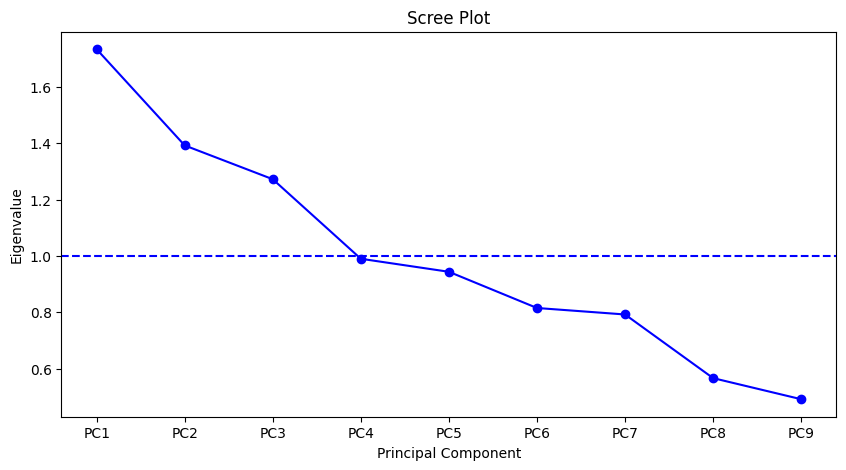

In [34]:
# Scree plot of eigenvalues
ax = summary_df['Eigenvalue'].plot(marker='o', color='blue', figsize=(10,5))
ax.axhline(y=1, color='b', linestyle='--')

ax.set_title('Scree Plot')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Eigenvalue');


In [35]:
# Component matrix (correlations)
component_matrix = pd.DataFrame(
    pcs.components_.T * np.sqrt(eig),
    index=scaled_df.columns,
    columns=pc_names
)
component_matrix.round(3)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
lead_time,0.312,0.081,-0.590,-0.131,0.287,0.607,0.260,0.050,-0.096
previous_cancellations,-0.198,0.332,-0.356,-0.509,0.489,-0.373,-0.282,0.086,0.014
previous_bookings_not_canceled,-0.502,0.630,0.106,-0.081,-0.027,0.089,0.244,-0.515,0.006
booking_changes,0.153,0.227,0.189,0.684,0.642,-0.089,0.008,-0.008,-0.034
is_repeated_guest,-0.576,0.546,0.118,0.100,-0.159,0.110,0.167,0.530,-0.023
total_of_special_requests,0.142,0.161,0.657,-0.256,0.142,0.464,-0.470,0.010,-0.002
stays_in_weekend_nights,0.649,0.491,-0.010,-0.003,-0.273,-0.185,-0.066,-0.005,-0.474
stays_in_week_nights,0.684,0.492,-0.058,0.011,-0.163,-0.059,0.036,0.037,0.504
adr,0.287,-0.146,0.549,-0.404,0.252,-0.164,0.576,0.090,-0.032


In [45]:
# import Resort Hotel data
Resort = "/content/H1.csv"
df = pd.read_csv(Resort)

#Shows each columns data type and number of non-null values.
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40060 entries, 0 to 40059
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   IsCanceled                   40060 non-null  int64  
 1   LeadTime                     40060 non-null  int64  
 2   ArrivalDateYear              40060 non-null  int64  
 3   ArrivalDateMonth             40060 non-null  object 
 4   ArrivalDateWeekNumber        40060 non-null  int64  
 5   ArrivalDateDayOfMonth        40060 non-null  int64  
 6   StaysInWeekendNights         40060 non-null  int64  
 7   StaysInWeekNights            40060 non-null  int64  
 8   Adults                       40060 non-null  int64  
 9   Children                     40060 non-null  int64  
 10  Babies                       40060 non-null  int64  
 11  Meal                         40060 non-null  object 
 12  Country                      39596 non-null  object 
 13  MarketSegment   

In [53]:
# Load the Resort Hotel dataset specifically to ensure correct data is plotted
resort_df= pd.read_csv("/content/H1.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79330 entries, 0 to 79329
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   IsCanceled                   79330 non-null  int64  
 1   LeadTime                     79330 non-null  int64  
 2   ArrivalDateYear              79330 non-null  int64  
 3   ArrivalDateMonth             79330 non-null  object 
 4   ArrivalDateWeekNumber        79330 non-null  int64  
 5   ArrivalDateDayOfMonth        79330 non-null  int64  
 6   StaysInWeekendNights         79330 non-null  int64  
 7   StaysInWeekNights            79330 non-null  int64  
 8   Adults                       79330 non-null  int64  
 9   Children                     79326 non-null  float64
 10  Babies                       79330 non-null  int64  
 11  Meal                         79330 non-null  object 
 12  Country                      79306 non-null  object 
 13  MarketSegment   

In [54]:
# Import City Hotel data
city_df = "/content/H2.csv"
df = pd.read_csv(city)
# Shows each columns data type and number of non-null values.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79330 entries, 0 to 79329
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   IsCanceled                   79330 non-null  int64  
 1   LeadTime                     79330 non-null  int64  
 2   ArrivalDateYear              79330 non-null  int64  
 3   ArrivalDateMonth             79330 non-null  object 
 4   ArrivalDateWeekNumber        79330 non-null  int64  
 5   ArrivalDateDayOfMonth        79330 non-null  int64  
 6   StaysInWeekendNights         79330 non-null  int64  
 7   StaysInWeekNights            79330 non-null  int64  
 8   Adults                       79330 non-null  int64  
 9   Children                     79326 non-null  float64
 10  Babies                       79330 non-null  int64  
 11  Meal                         79330 non-null  object 
 12  Country                      79306 non-null  object 
 13  MarketSegment   

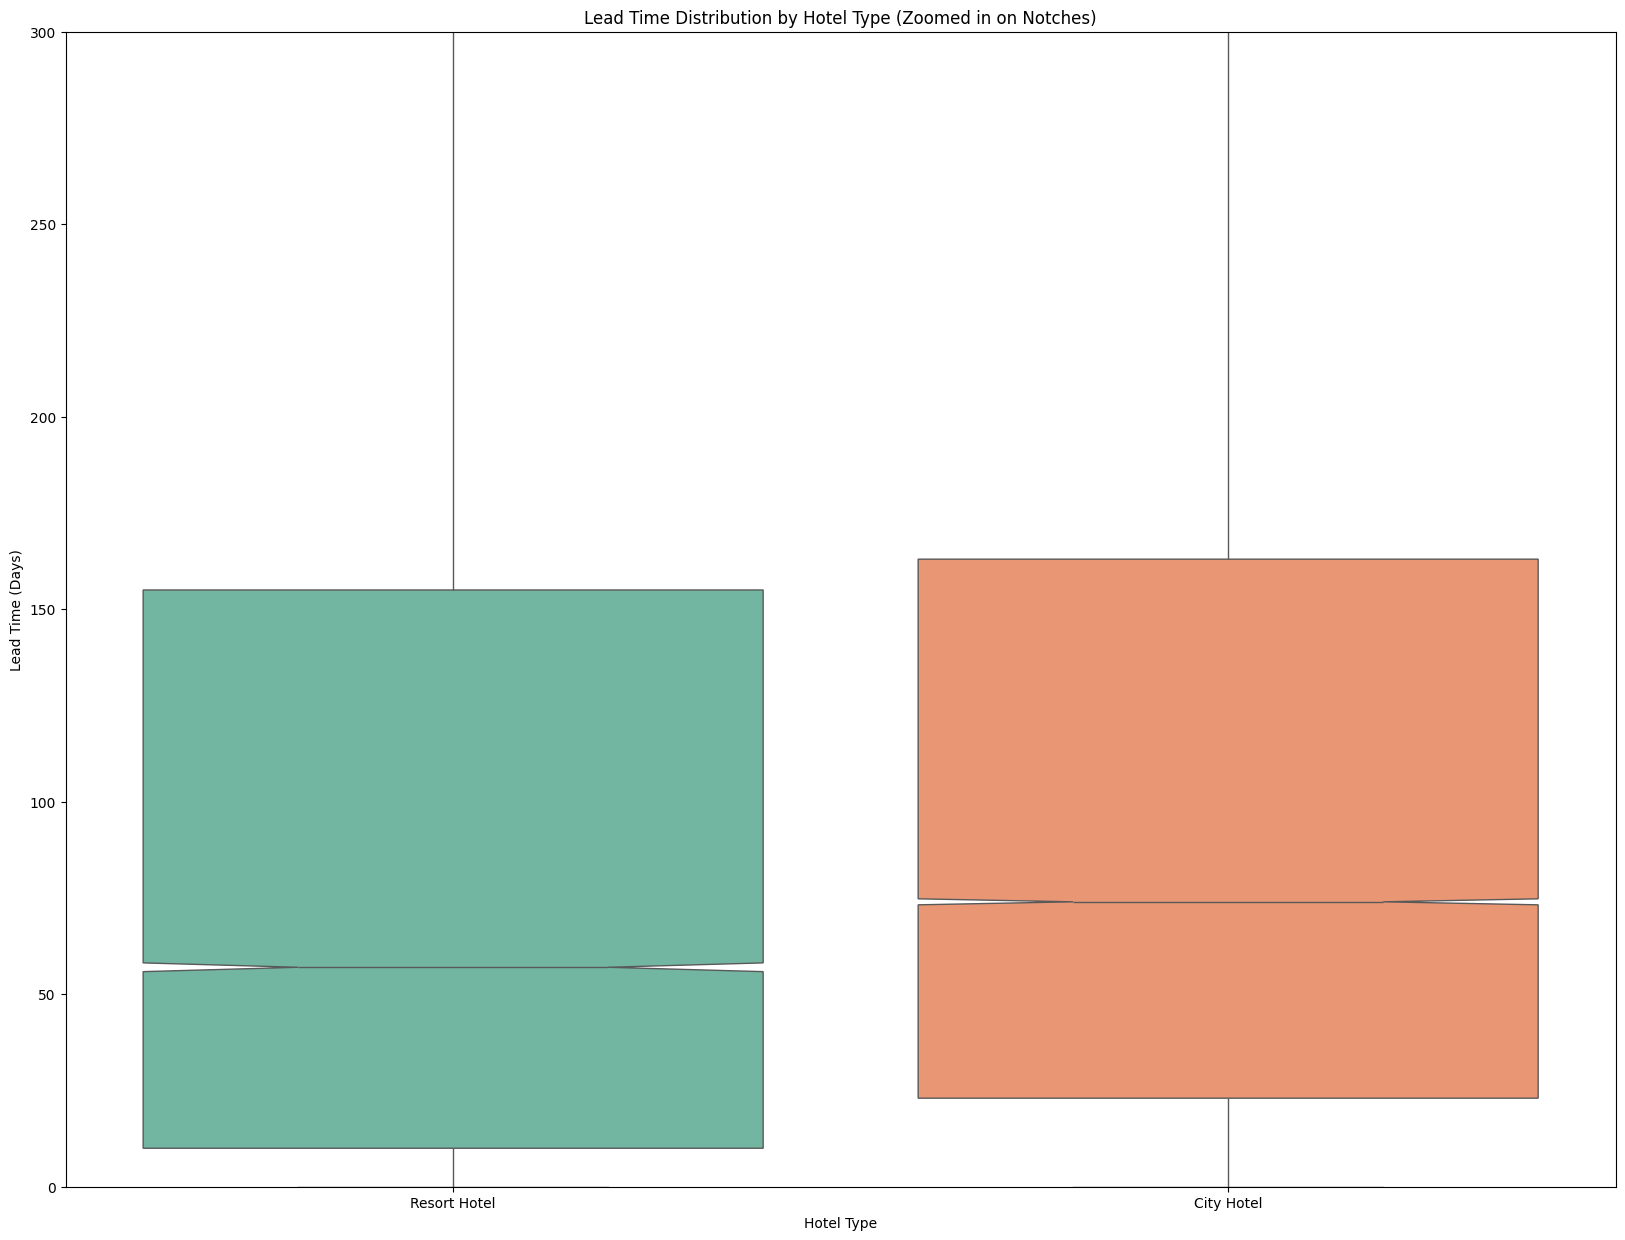

In [65]:
# Load both datasets as pandas DataFrames
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

resort_df = pd.read_csv("/content/H1.csv")
city_df = pd.read_csv("/content/H2.csv")

# Label each hotel type
resort_df["Hotel"] = "Resort Hotel"
city_df["Hotel"] = "City Hotel"

# Combine datasets
df_combined = pd.concat([resort_df, city_df], ignore_index=True)

# Create the notched box plot with zoomed-in y-axis to see notches clearly
plt.figure(figsize=(20, 15))
sns.boxplot(
    data=df_combined,
    x="Hotel",
    y="LeadTime",
    hue="Hotel",
    notch=True,
    showfliers=False,
    palette="Set2",
    legend=False
)

# Set limit to zoom in on the boxes and notches, ignoring extreme outliers
plt.ylim(0, 300)

plt.title("Lead Time Distribution by Hotel Type (Zoomed in on Notches)")
plt.xlabel("Hotel Type")
plt.ylabel("Lead Time (Days)")
plt.show()

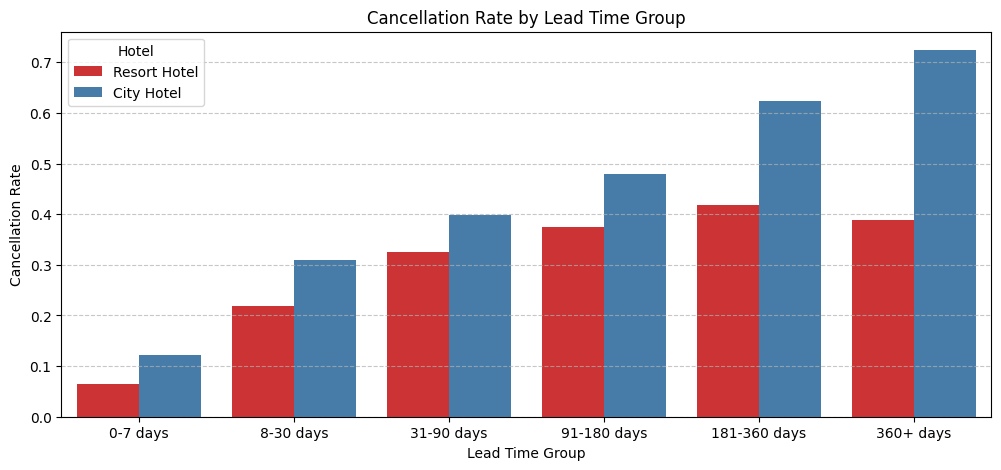

In [66]:
# Create lead time groups for easier profile interpretation
df_combined['LeadTimeGroup'] = pd.cut(
    df_combined['LeadTime'],
    bins=[-1, 7, 30, 90, 180, 360, np.inf],
    labels=['0-7 days', '8-30 days', '31-90 days', '91-180 days', '181-360 days', '360+ days']
)

# 1. Compare cancellation rates by LeadTimeGroup
plt.figure(figsize=(12, 5))
sns.barplot(data=df_combined, x='LeadTimeGroup', y='IsCanceled', hue='Hotel', palette='Set1', errorbar=None)
plt.title('Cancellation Rate by Lead Time Group')
plt.ylabel('Cancellation Rate')
plt.xlabel('Lead Time Group')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

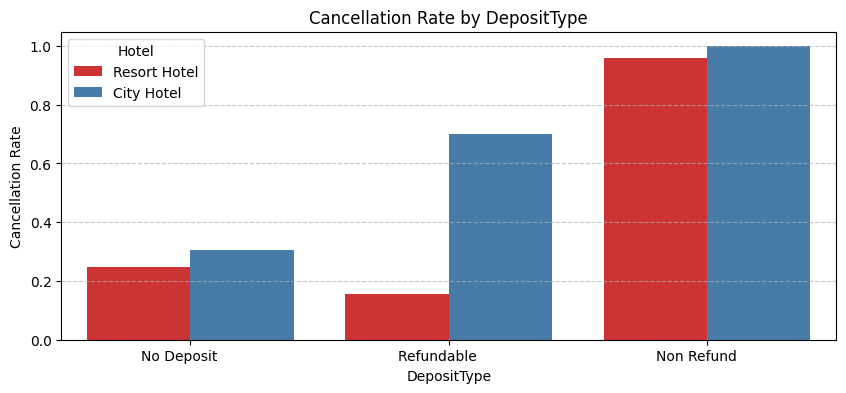

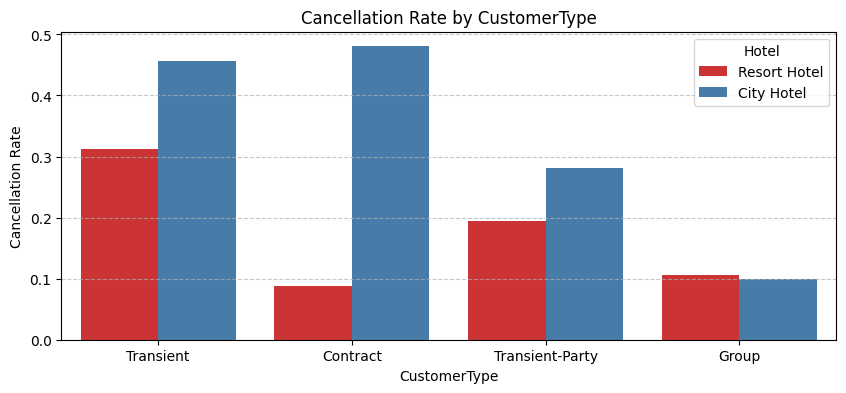

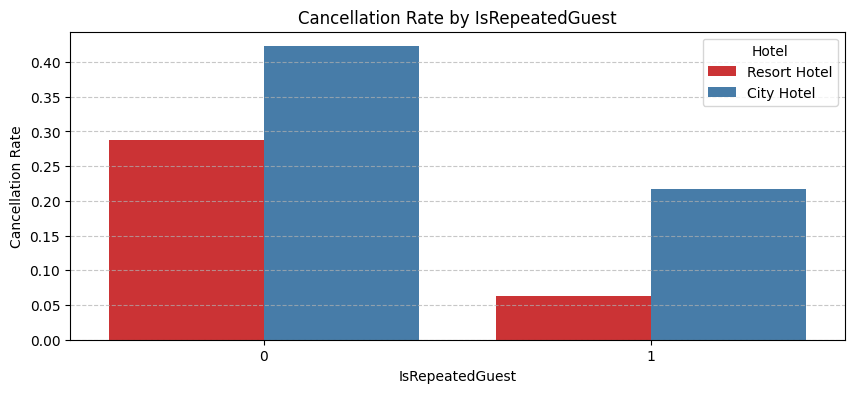

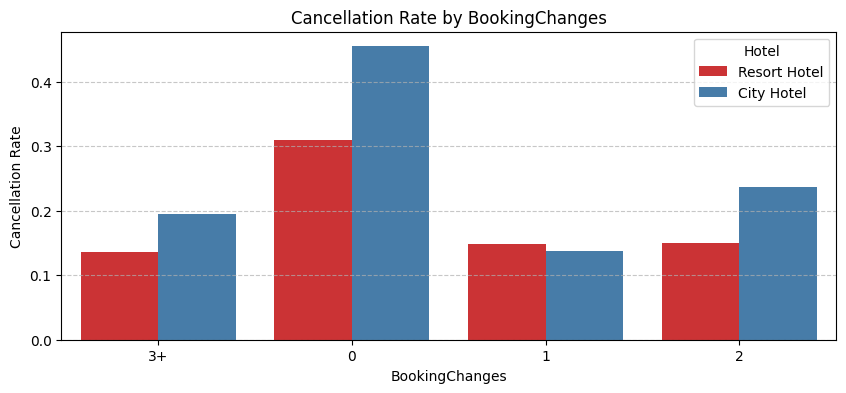

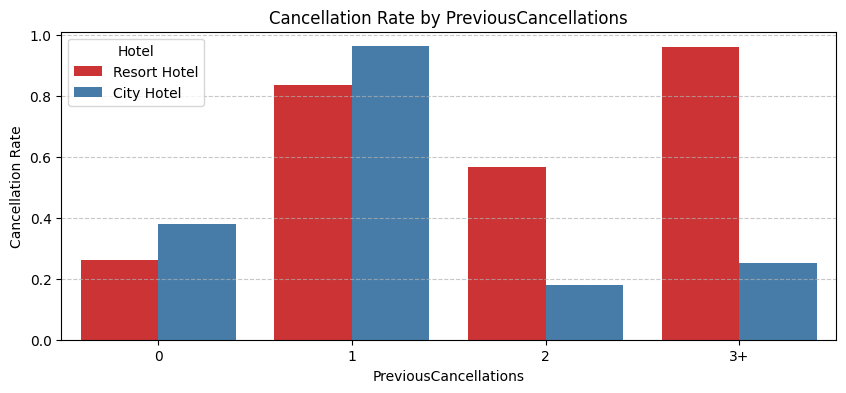

In [67]:
# 2. Analyze Cancellation Rates across other profile attributes
profile_cols = ['DepositType', 'CustomerType', 'IsRepeatedGuest', 'BookingChanges', 'PreviousCancellations']

for col in profile_cols:
    # Treat columns with too many unique numeric values simpler by binning or showing top values
    if col in ['BookingChanges', 'PreviousCancellations']:
        # Group high numbers to simplify visualization
        temp_df = df_combined.copy()
        temp_df[col] = temp_df[col].apply(lambda x: str(x) if x < 3 else '3+')
    else:
        temp_df = df_combined

    plt.figure(figsize=(10, 4))
    sns.barplot(data=temp_df, x=col, y='IsCanceled', hue='Hotel', palette='Set1', errorbar=None)
    plt.title(f'Cancellation Rate by {col}')
    plt.ylabel('Cancellation Rate')
    plt.xlabel(col)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(


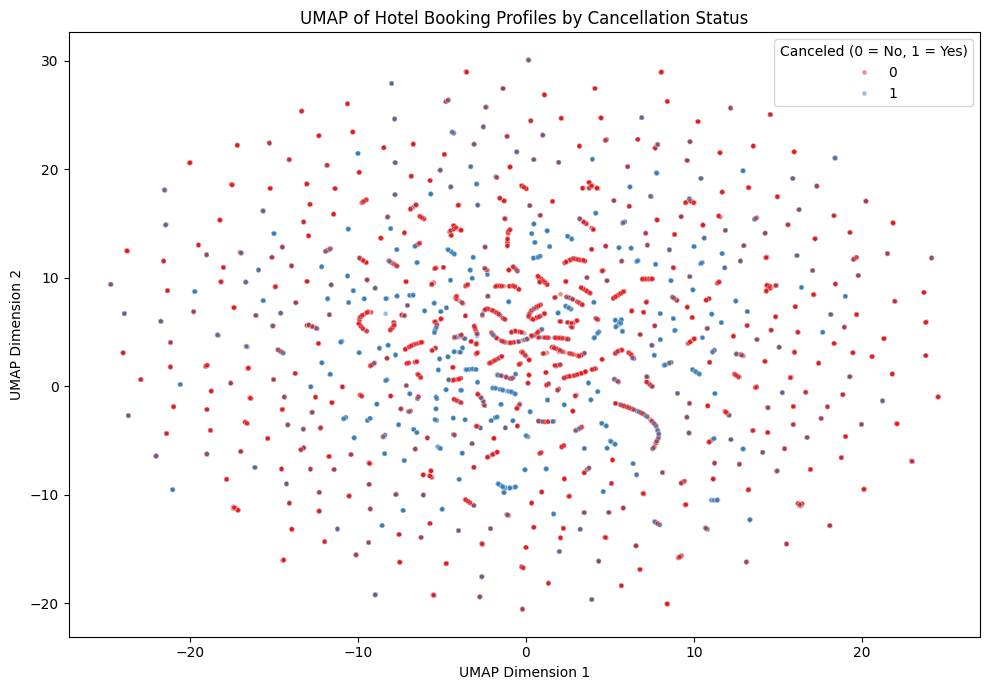

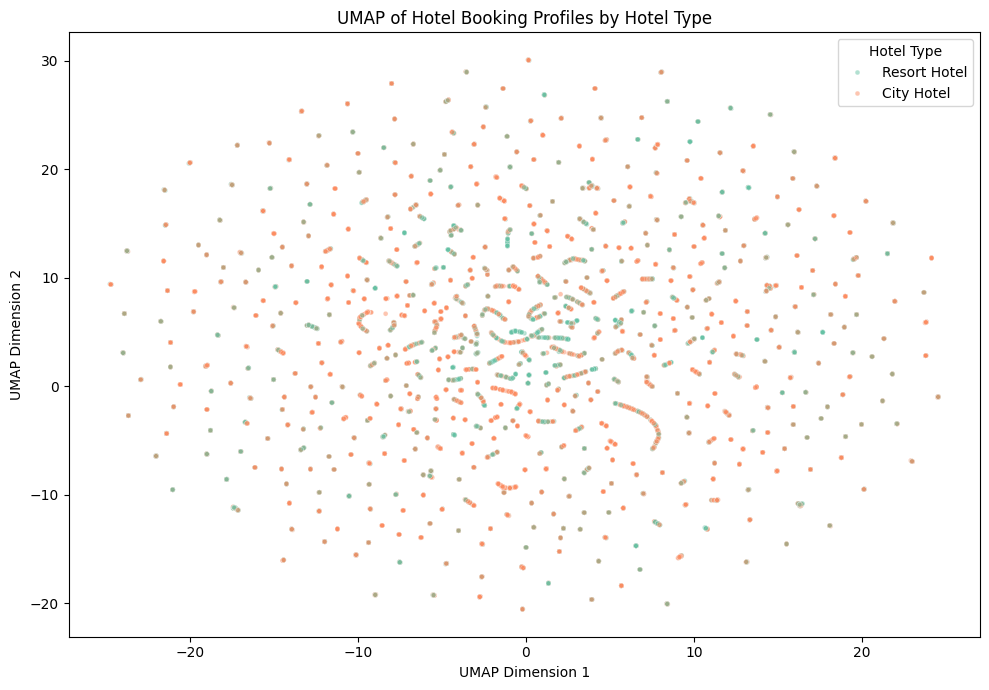

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import umap

# Combine the datasets
df = pd.read_csv(path)

# Select the six variables for your descriptive analysis (using correct lowercase names)
numeric_features = [
    "lead_time",
    "previous_cancellations",
    "booking_changes"
]

categorical_features = [
    "deposit_type",
    "customer_type",
    "is_repeated_guest"
]

# Keep rows with complete values for the selected variables
df = df.dropna(
    subset=numeric_features + categorical_features + ["is_canceled", "hotel"]
).copy()

# Sample records to make UMAP faster to run and plot
df_sample = df.sample(
    n=min(20000, len(df)),
    random_state=42
).copy()

# Scale numerical features and encode categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

X = preprocessor.fit_transform(df_sample)

# Run UMAP
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=42
)

embedding = reducer.fit_transform(X)

# Save the two UMAP dimensions
df_sample["UMAP1"] = embedding[:, 0]
df_sample["UMAP2"] = embedding[:, 1]

# Plot 1: Color by cancellation status
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df_sample,
    x="UMAP1",
    y="UMAP2",
    hue="is_canceled",
    palette="Set1",
    alpha=0.5,
    s=12
)

plt.title("UMAP of Hotel Booking Profiles by Cancellation Status")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.legend(title="Canceled (0 = No, 1 = Yes)")
plt.tight_layout()
plt.show()

# Plot 2: Color by hotel type
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df_sample,
    x="UMAP1",
    y="UMAP2",
    hue="hotel",
    palette="Set2",
    alpha=0.5,
    s=12
)

plt.title("UMAP of Hotel Booking Profiles by Hotel Type")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.legend(title="Hotel Type")
plt.tight_layout()
plt.show()

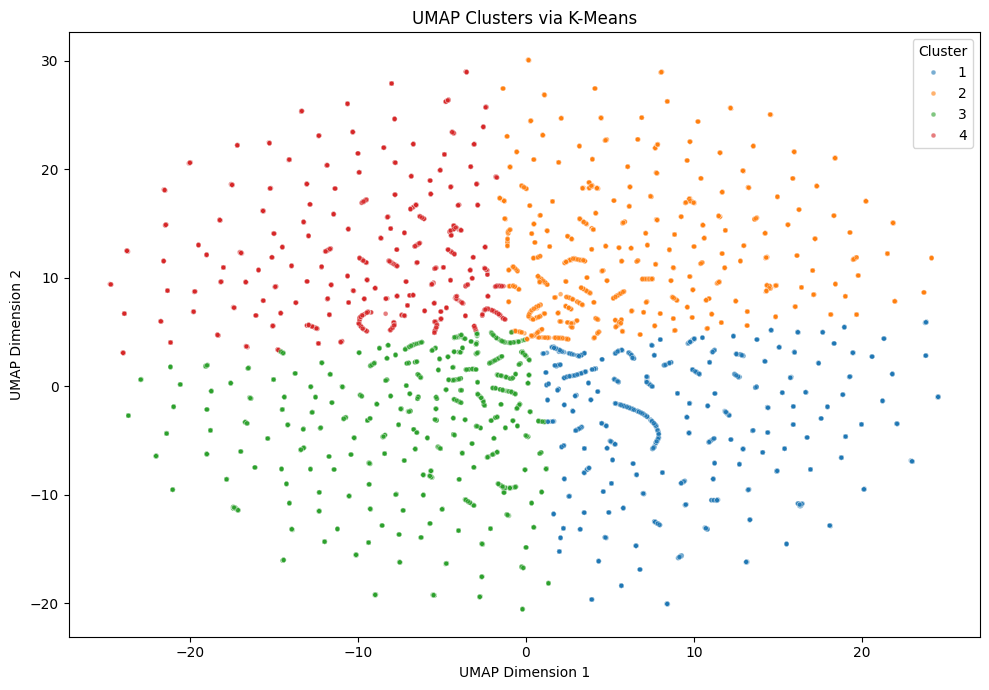

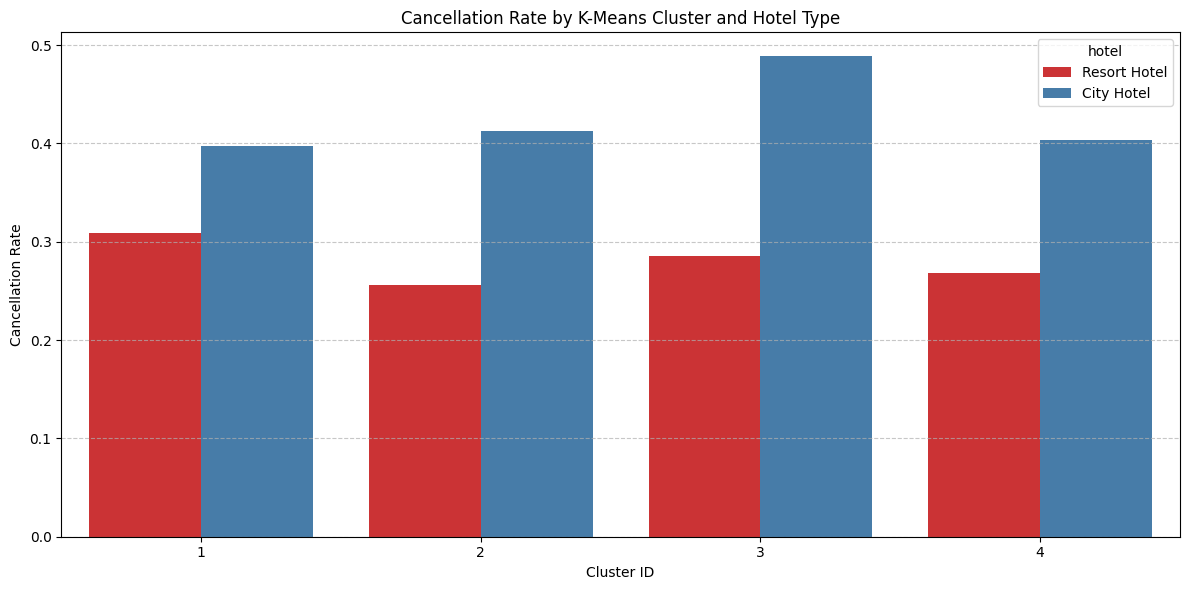

In [75]:
from sklearn.cluster import KMeans

# Extract the 2D UMAP dimensions
umap_features = df_sample[['UMAP1', 'UMAP2']]

# Perform K-Means Clustering (using 4 clusters as a starting point)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
# Add 1 to start cluster numbering from 1 instead of 0
df_sample['cluster'] = kmeans.fit_predict(umap_features) + 1

# Plot the UMAP projections colored by cluster
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df_sample,
    x="UMAP1",
    y="UMAP2",
    hue="cluster",
    palette="tab10",
    alpha=0.6,
    s=12
)
plt.title("UMAP Clusters via K-Means")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

# Calculate and plot cancellation rates by cluster and hotel type
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_sample,
    x='cluster',
    y='is_canceled',
    hue='hotel',
    palette='Set1',
    errorbar=None
)
plt.title("Cancellation Rate by K-Means Cluster and Hotel Type")
plt.xlabel("Cluster ID")
plt.ylabel("Cancellation Rate")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()